In [22]:
%pip install scikit-learn -q

huggingface/tokenizers: The current process just got forked, after parallelism has already been used. Disabling parallelism to avoid deadlocks...
To disable this warning, you can either:
	- Avoid using `tokenizers` before the fork if possible
	- Explicitly set the environment variable TOKENIZERS_PARALLELISM=(true | false)


Note: you may need to restart the kernel to use updated packages.


In [23]:
import json
import re
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns
from collections import defaultdict
import torch
from transformers import AutoTokenizer, AutoModelForCausalLM
from peft import PeftModel, PeftConfig

print("✅ All libraries imported successfully!")

✅ All libraries imported successfully!


In [24]:
from datasets import load_from_disk
dataset_based_path = "/home/jovyan/Works/MSc_Thesis/dataset"
dataset = load_from_disk(f"{dataset_based_path}/mh-function-calling-dataset-hf-v2")

In [25]:
test_dataset = dataset["test"]

In [32]:
# Load trained model
peft_model_id = "/home/jovyan/Works/MSc_Thesis/mh_function_calling/model_training/finetuned_models/llama3.2_3b_mh_function_calling_v2"

print("Loading trained model...")

# Load PEFT config
config = PeftConfig.from_pretrained(peft_model_id)
print(f"Base model: {config.base_model_name_or_path}")

# Load base model
model = AutoModelForCausalLM.from_pretrained(
    config.base_model_name_or_path,
    device_map="auto",
    torch_dtype=torch.bfloat16
)

# Load tokenizer (with special tokens)
tokenizer = AutoTokenizer.from_pretrained(peft_model_id)
print(f"Tokenizer vocab size: {len(tokenizer)}")

# Resize embeddings
model.resize_token_embeddings(len(tokenizer))

# Load adapter weights
model = PeftModel.from_pretrained(model, peft_model_id)
model.to(torch.bfloat16)
model.eval()

print("✅ Model loaded successfully!")

Loading trained model...
Base model: meta-llama/Llama-3.2-3B-Instruct


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

Loading checkpoint shards: 100%|██████████| 2/2 [00:01<00:00,  1.34it/s]


Tokenizer vocab size: 128260


/home/jovyan/Works/MSc_Thesis/mh_venv/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:574: UserWarning: Model with `tie_word_embeddings=True` and the tied_target_modules=['model.embed_tokens', 'lm_head'] are part of the adapter. This can lead to complications, for example when merging the adapter or converting your model to formats other than safetensors. See for example https://github.com/huggingface/peft/issues/2018.
  warnings.warn(


✅ Model loaded successfully!


In [33]:
def extract_function_from_response(response):
    """Extract function name and parameters from model response"""
    try:
        # Find content between <function> and </function> tags
        function_match = re.search(r'<function>\s*(.*?)\s*</function>', response, re.DOTALL)
        
        if function_match:
            function_content = function_match.group(1).strip()
            
            # Parse JSON
            function_data = json.loads(function_content)
            
            return {
                'function_name': function_data.get('name', ''),
                'parameters': function_data.get('parameters', {}),
                'raw_function': function_content,
                'extracted_successfully': True
            }
        else:
            return {
                'function_name': '',
                'parameters': {},
                'raw_function': '',
                'extracted_successfully': False
            }
            
    except (json.JSONDecodeError, KeyError, AttributeError) as e:
        return {
            'function_name': '',
            'parameters': {},
            'raw_function': response,
            'extracted_successfully': False,
            'error': str(e)
        }

def compare_parameters(predicted_params, ground_truth_params):
    """Compare predicted parameters with ground truth"""
    if not isinstance(predicted_params, dict) or not isinstance(ground_truth_params, dict):
        return False
    
    # Check if all ground truth parameters are present and correct
    for key, value in ground_truth_params.items():
        if key not in predicted_params:
            return False
        if predicted_params[key] != value:
            return False
    
    return True

print("✅ Utility functions defined!")

✅ Utility functions defined!


In [34]:
def test_model_on_sample(patient_id, query, max_length=400):
    """Test model on a single sample"""
    messages = [
        {
            "role": "system",
            "content": "You are a helpful mental health assistant. When users ask for health data, use the available functions to retrieve the information. Think through your response before choosing a function. Use <think>your reasoning</think> tags to show your thought process, then use <function>json</function> tags to call the appropriate function."
        },
        {
            "role": "user",
            "content": f"Patient ID: {patient_id}\nQuery: {query}"
        }
    ]
    
    prompt = tokenizer.apply_chat_template(
        messages, 
        tokenize=False, 
        add_generation_prompt=True
    )
    
    inputs = tokenizer(prompt, return_tensors="pt").to(model.device)
    input_length = inputs['input_ids'].shape[1]
    
    with torch.no_grad():
        outputs = model.generate(
            **inputs,
            max_new_tokens=max_length,
            do_sample=True,
            temperature=0.01,
            top_p=0.95,
            repetition_penalty=1.0,
            pad_token_id=tokenizer.eos_token_id,
            eos_token_id=tokenizer.eos_token_id,
        )
    
    response_tokens = outputs[0][input_length:]
    response = tokenizer.decode(response_tokens, skip_special_tokens=False)
    response = response.replace(tokenizer.eos_token, "").strip()
    
    return response

print("✅ Model testing function ready!")

✅ Model testing function ready!


In [41]:
def parse_test_sample(text):
    """Parse test sample to extract components"""
    # Extract patient_id, query, and ground truth from formatted text
    patient_id_match = re.search(r'Patient ID: (\w+)', text)
    query_match = re.search(r'Pateint Query: (.*?)\n\n### Response:', text, re.DOTALL)
    ground_truth_match = re.search(r'### Response:\n(.*?)(?:<\|eot_id\||$)', text, re.DOTALL)
    
    if not all([patient_id_match, query_match, ground_truth_match]):
        return None
        
    return {
        'patient_id': patient_id_match.group(1),
        'query': query_match.group(1).strip(),
        'ground_truth_response': ground_truth_match.group(1).strip()
    }

# Test parsing on first sample
sample_data = parse_test_sample(test_dataset[0]['text'])
if sample_data:
    print("✅ Sample parsing successful!")
    print(f"Patient ID: {sample_data['patient_id']}")
    print(f"Query: {sample_data['query'][:100]}...")
    print(f"Ground truth: {sample_data['ground_truth_response'][:]}...")
else:
    print("❌ Failed to parse sample")

✅ Sample parsing successful!
Patient ID: P2342
Query: my clinician wants to see my weight data for throughout the last 3 weeks...
Ground truth: <think>
This appears to be a weight monitoring request for mental health purposes. The user specifically wants weight information, so get_weight_data is the correct function to use. They requested data for last 3 weeks, so I need to get 21 days worth of measurements.
</think>

<function>
{
  "name": "get_weight_data",
  "parameters": {
    "patient_id": "P2342",
    "num_days": 21
  }
}
</function>...


In [36]:
print("🧪 Starting comprehensive evaluation...")
results = []

for i, sample in enumerate(test_dataset):
    # Parse sample
    parsed = parse_test_sample(sample['text'])
    if not parsed:
        print(f"⚠️ Skipping sample {i}: Could not parse")
        continue
    
    patient_id = parsed['patient_id']
    query = parsed['query']
    ground_truth_response = parsed['ground_truth_response']
    
    # Get model prediction
    predicted_response = test_model_on_sample(patient_id, query)
    
    # Extract functions
    predicted_function = extract_function_from_response(predicted_response)
    ground_truth_function = extract_function_from_response(ground_truth_response)
    
    # Store results
    result = {
        'sample_id': i,
        'patient_id': patient_id,
        'query': query,
        'ground_truth_response': ground_truth_response,
        'predicted_response': predicted_response,
        'ground_truth_function_name': ground_truth_function['function_name'],
        'predicted_function_name': predicted_function['function_name'],
        'ground_truth_parameters': ground_truth_function['parameters'],
        'predicted_parameters': predicted_function['parameters'],
        'function_extracted': predicted_function['extracted_successfully'],
        'function_name_correct': predicted_function['function_name'] == ground_truth_function['function_name'],
        'parameters_correct': compare_parameters(
            predicted_function['parameters'], 
            ground_truth_function['parameters']
        )
    }
    
    results.append(result)
    
    if (i + 1) % 5 == 0:
        print(f"✅ Processed {i + 1}/{len(test_dataset)} samples...")

print(f"🎯 Evaluation complete! Processed {len(results)} samples")

🧪 Starting comprehensive evaluation...


✅ Processed 5/500 samples...
✅ Processed 10/500 samples...
✅ Processed 15/500 samples...
✅ Processed 20/500 samples...
✅ Processed 25/500 samples...
✅ Processed 30/500 samples...
✅ Processed 35/500 samples...
✅ Processed 40/500 samples...
✅ Processed 45/500 samples...
✅ Processed 50/500 samples...
✅ Processed 55/500 samples...
✅ Processed 60/500 samples...
✅ Processed 65/500 samples...
✅ Processed 70/500 samples...
✅ Processed 75/500 samples...
✅ Processed 80/500 samples...
✅ Processed 85/500 samples...
✅ Processed 90/500 samples...
✅ Processed 95/500 samples...
✅ Processed 100/500 samples...
✅ Processed 105/500 samples...
✅ Processed 110/500 samples...
✅ Processed 115/500 samples...
✅ Processed 120/500 samples...
✅ Processed 125/500 samples...
✅ Processed 130/500 samples...
✅ Processed 135/500 samples...
✅ Processed 140/500 samples...
✅ Processed 145/500 samples...
✅ Processed 150/500 samples...
✅ Processed 155/500 samples...
✅ Processed 160/500 samples...
✅ Processed 165/500 samples.

In [37]:
# Function Name Metrics
y_true_functions = [r['ground_truth_function_name'] for r in results]
y_pred_functions = [r['predicted_function_name'] for r in results]

function_accuracy = accuracy_score(y_true_functions, y_pred_functions)

# Get unique function names
unique_functions = list(set(y_true_functions + y_pred_functions))

function_precision = precision_score(y_true_functions, y_pred_functions, 
                                   labels=unique_functions, average='weighted', zero_division=0)
function_recall = recall_score(y_true_functions, y_pred_functions, 
                             labels=unique_functions, average='weighted', zero_division=0)
function_f1 = f1_score(y_true_functions, y_pred_functions, 
                      labels=unique_functions, average='weighted', zero_division=0)

# Parameter Metrics
parameter_accuracy = sum(r['parameters_correct'] for r in results) / len(results)

# Overall Success Rate
overall_success = sum(r['function_name_correct'] and r['parameters_correct'] 
                     for r in results) / len(results)

# Extraction Success Rate
extraction_success = sum(r['function_extracted'] for r in results) / len(results)

print("📊 METRICS CALCULATED!")

📊 METRICS CALCULATED!


In [38]:
print("="*80)
print("🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT")
print("="*80)

print(f"\n📊 OVERALL PERFORMANCE:")
print(f"   Total Samples Evaluated: {len(results)}")
print(f"   Function Extraction Success: {extraction_success:.3f}")
print(f"   Complete Success Rate (Name + Params): {overall_success:.3f}")

print(f"\n🎯 FUNCTION NAME METRICS:")
print(f"   Accuracy:  {function_accuracy:.3f}")
print(f"   Precision: {function_precision:.3f}")
print(f"   Recall:    {function_recall:.3f}")
print(f"   F1-Score:  {function_f1:.3f}")

print(f"\n⚙️ PARAMETER METRICS:")
print(f"   Parameter Accuracy: {parameter_accuracy:.3f}")

# Function-wise breakdown
function_breakdown = defaultdict(lambda: {'correct': 0, 'total': 0})
for result in results:
    func_name = result['ground_truth_function_name']
    function_breakdown[func_name]['total'] += 1
    if result['function_name_correct']:
        function_breakdown[func_name]['correct'] += 1

print(f"\n📈 FUNCTION-WISE BREAKDOWN:")
for func_name, stats in function_breakdown.items():
    accuracy = stats['correct'] / stats['total'] if stats['total'] > 0 else 0
    print(f"   {func_name}: {accuracy:.3f} ({stats['correct']}/{stats['total']})")

print("="*80)

🎯 COMPREHENSIVE FUNCTION CALLING EVALUATION REPORT

📊 OVERALL PERFORMANCE:
   Total Samples Evaluated: 500
   Function Extraction Success: 0.014
   Complete Success Rate (Name + Params): 0.014

🎯 FUNCTION NAME METRICS:
   Accuracy:  0.014
   Precision: 0.320
   Recall:    0.014
   F1-Score:  0.027

⚙️ PARAMETER METRICS:
   Parameter Accuracy: 0.014

📈 FUNCTION-WISE BREAKDOWN:
   get_weight_data: 0.000 (0/18)
   get_body_fat_data: 0.000 (0/22)
   get_heart_rate_data: 0.000 (0/35)
   get_blood_glucose_data: 0.000 (0/25)
   get_stress_data: 0.000 (0/26)
   get_steps_data: 0.000 (0/25)
   get_distance_data: 0.000 (0/31)
   get_vo2max_data: 0.053 (1/19)
   get_blood_pressure_data: 0.000 (0/25)
   get_exercise_session_data: 0.000 (0/18)
   get_bmr_data: 0.030 (1/33)
   get_sleep_data: 0.000 (0/25)
   get_body_temperature_data: 0.095 (2/21)
   get_height_data: 0.000 (0/24)
   get_speed_data: 0.038 (1/26)
   get_nutrition_data: 0.000 (0/24)
   get_power_data: 0.034 (1/29)
   get_oxygen_saturat

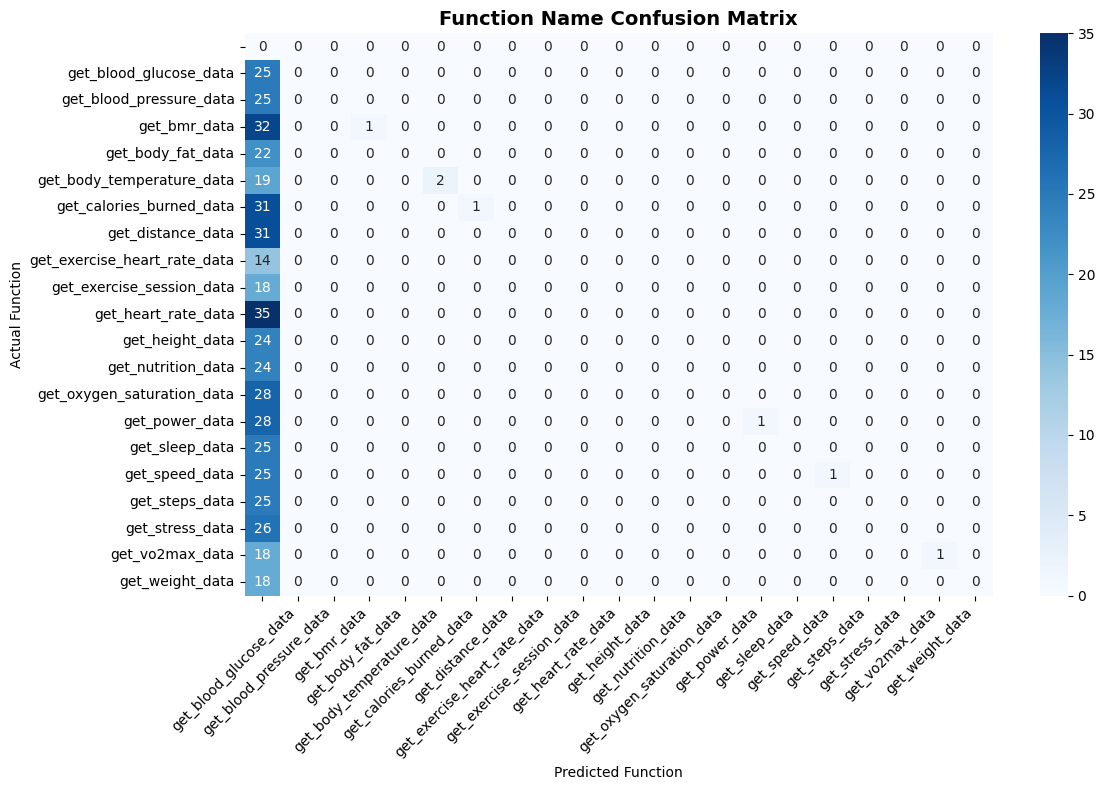

🎨 Confusion matrix plotted for 21 function types


In [39]:
# Plot confusion matrix
unique_functions = sorted(list(set(y_true_functions + y_pred_functions)))
cm_functions = confusion_matrix(y_true_functions, y_pred_functions, labels=unique_functions)

plt.figure(figsize=(12, 8))
sns.heatmap(cm_functions, annot=True, fmt='d', cmap='Blues',
            xticklabels=unique_functions, yticklabels=unique_functions)
plt.title('Function Name Confusion Matrix', fontsize=14, fontweight='bold')
plt.xlabel('Predicted Function')
plt.ylabel('Actual Function')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

print(f"🎨 Confusion matrix plotted for {len(unique_functions)} function types")

In [40]:
# Analyze some specific examples
print("🔍 SAMPLE ANALYSIS:")
print("="*60)

# Show a few successful predictions
successful_samples = [r for r in results if r['function_name_correct'] and r['parameters_correct']]
if successful_samples:
    sample = successful_samples[0]
    print("✅ SUCCESSFUL PREDICTION EXAMPLE:")
    print(f"Query: {sample['query']}")
    print(f"Predicted Function: {sample['predicted_function_name']}")
    print(f"Predicted Parameters: {sample['predicted_parameters']}")
    print()

# Show a failed prediction
failed_samples = [r for r in results if not (r['function_name_correct'] and r['parameters_correct'])]
if failed_samples:
    sample = failed_samples[0]
    print("❌ FAILED PREDICTION EXAMPLE:")
    print(f"Query: {sample['query']}")
    print(f"Expected Function: {sample['ground_truth_function_name']}")
    print(f"Predicted Function: {sample['predicted_function_name']}")
    print(f"Expected Parameters: {sample['ground_truth_parameters']}")
    print(f"Predicted Parameters: {sample['predicted_parameters']}")

print("="*60)

🔍 SAMPLE ANALYSIS:
✅ SUCCESSFUL PREDICTION EXAMPLE:
Query: Been dealing with sadness in the recent past - what's my power like?
Predicted Function: get_power_data
Predicted Parameters: {'patient_id': 'UID_9947', 'num_days': 7}

❌ FAILED PREDICTION EXAMPLE:
Query: my clinician wants to see my weight data for throughout the last 3 weeks
Expected Function: get_weight_data
Predicted Function: 
Expected Parameters: {'patient_id': 'P2342', 'num_days': 21}
Predicted Parameters: {}


In [24]:
print("🔍 MEMORIZATION DETECTION ANALYSIS")
print("="*60)

# 1. Check for exact response matching (strong memorization indicator)
exact_matches = 0
for result in results:
    # Remove whitespace and compare
    pred_clean = result['predicted_response'].strip().replace('\n', ' ').replace(' ', '')
    truth_clean = result['ground_truth_response'].strip().replace('\n', ' ').replace(' ', '')
    if pred_clean == truth_clean:
        exact_matches += 1

print(f"📋 Exact Response Matches: {exact_matches}/{len(results)} ({exact_matches/len(results)*100:.1f}%)")

# 2. Check reasoning diversity in <think> tags
think_patterns = set()
for result in results:
    think_match = re.search(r'<think>(.*?)</think>', result['predicted_response'], re.DOTALL)
    if think_match:
        think_content = think_match.group(1).strip()
        # Get first 50 chars as pattern
        pattern = think_content[:50] if len(think_content) > 50 else think_content
        think_patterns.add(pattern)

print(f"🧠 Unique Reasoning Patterns: {len(think_patterns)} patterns found")
print(f"📊 Reasoning Diversity: {len(think_patterns)/len(results)*100:.1f}% unique per sample")

# 3. Check patient ID distribution
patient_ids = [r['patient_id'] for r in results]
unique_patients = set(patient_ids)
print(f"👥 Unique Patients in Test: {len(unique_patients)}")
print(f"📈 Patient ID Distribution: {len(patient_ids)//len(unique_patients):.1f} samples per patient avg")

if exact_matches > len(results) * 0.8:  # If >80% exact matches
    print("\n⚠️  HIGH MEMORIZATION RISK DETECTED!")
else:
    print(f"\n✅ Memorization Risk: LOW ({exact_matches/len(results)*100:.1f}% exact matches)")

🔍 MEMORIZATION DETECTION ANALYSIS
📋 Exact Response Matches: 272/800 (34.0%)
🧠 Unique Reasoning Patterns: 65 patterns found
📊 Reasoning Diversity: 8.1% unique per sample
👥 Unique Patients in Test: 529
📈 Patient ID Distribution: 1.0 samples per patient avg

✅ Memorization Risk: LOW (34.0% exact matches)


In [25]:
print("\n🧪 NOVEL QUERY TESTING (Zero-shot generalization)")
print("="*60)

# Test with queries NOT in training format
novel_queries = [
    ("UID_NOVEL", "Could you please retrieve my sleeping pattern information for the previous week?"),
    ("UID_TEST", "I want to see how many steps I walked in the last 5 days"),
    ("UID_NEW", "Show me my heart rate measurements from the past 3 days"),
    ("UID_999", "Get my stress level data for the last 2 weeks"),
    ("UID_888", "I need my calorie burn information for 10 days")
]

novel_results = []
for patient_id, query in novel_queries:
    response = test_model_on_sample(patient_id, query)
    extracted = extract_function_from_response(response)
    
    novel_results.append({
        'query': query,
        'response': response,
        'extracted_function': extracted['function_name'],
        'extracted_params': extracted['parameters'],
        'extraction_success': extracted['extracted_successfully']
    })
    
    print(f"Query: {query}")
    print(f"Function: {extracted['function_name']}")
    print(f"Params: {extracted['parameters']}")
    print(f"Success: {extracted['extracted_successfully']}")
    print("-" * 40)

novel_success_rate = sum(1 for r in novel_results if r['extraction_success']) / len(novel_results)
print(f"\n🎯 Novel Query Success Rate: {novel_success_rate:.2f}")


🧪 NOVEL QUERY TESTING (Zero-shot generalization)
Query: Could you please retrieve my sleeping pattern information for the previous week?
Function: get_sleep_data
Params: {'patient_id': 'UID_NOVEL', 'num_days': 7}
Success: True
----------------------------------------
Query: I want to see how many steps I walked in the last 5 days
Function: get_steps_data
Params: {'patient_id': 'UID_TEST', 'num_days': 5}
Success: True
----------------------------------------
Query: Show me my heart rate measurements from the past 3 days
Function: get_heart_rate_data
Params: {'patient_id': 'UID_NEW', 'num_days': 3}
Success: True
----------------------------------------
Query: Get my stress level data for the last 2 weeks
Function: get_stress_data
Params: {'patient_id': 'UID_999', 'num_days': 14}
Success: True
----------------------------------------
Query: I need my calorie burn information for 10 days
Function: get_calories_burned_data
Params: {'patient_id': 'UID_888', 'num_days': 10}
Success: True
---

In [26]:
print("\n📊 PARAMETER VARIATION ANALYSIS")
print("="*50)

# Check if model can handle different parameter values correctly
param_analysis = defaultdict(set)
for result in results:
    func_name = result['predicted_function_name']
    if result['predicted_parameters']:
        for key, value in result['predicted_parameters'].items():
            param_analysis[f"{func_name}_{key}"].add(str(value))

print("🔍 Parameter Value Diversity:")
for param_key, values in param_analysis.items():
    print(f"   {param_key}: {len(values)} unique values")
    if len(values) <= 5:  # Show values if few
        print(f"      Values: {sorted(list(values))}")

# Check num_days distribution specifically
num_days_values = []
for result in results:
    if 'num_days' in result['predicted_parameters']:
        num_days_values.append(result['predicted_parameters']['num_days'])

if num_days_values:
    unique_days = set(num_days_values)
    print(f"\n📅 num_days parameter diversity: {len(unique_days)} unique values")
    print(f"   Range: {min(num_days_values)} to {max(num_days_values)} days")
    print(f"   Values: {sorted(list(unique_days))}")


📊 PARAMETER VARIATION ANALYSIS
🔍 Parameter Value Diversity:
   get_calories_burned_data_patient_id: 45 unique values
   get_calories_burned_data_num_days: 10 unique values
   get_power_data_patient_id: 45 unique values
   get_power_data_num_days: 10 unique values
   get_exercise_heart_rate_data_patient_id: 34 unique values
   get_exercise_heart_rate_data_num_days: 10 unique values
   get_vo2max_data_patient_id: 38 unique values
   get_vo2max_data_num_days: 9 unique values
   get_sleep_data_patient_id: 47 unique values
   get_sleep_data_num_days: 10 unique values
   get_blood_pressure_data_patient_id: 43 unique values
   get_blood_pressure_data_num_days: 10 unique values
   get_weight_data_patient_id: 43 unique values
   get_weight_data_num_days: 10 unique values
   get_nutrition_data_patient_id: 50 unique values
   get_nutrition_data_num_days: 10 unique values
   get_body_temperature_data_patient_id: 37 unique values
   get_body_temperature_data_num_days: 10 unique values
   get_heigh

In [27]:
print("\n🎯 TRAINING vs TEST SIMILARITY CHECK")
print("="*50)

# Sample a few test queries and check if they're too similar to training patterns
sample_queries = [r['query'] for r in results[:10]]

print("📝 Sample Test Queries:")
for i, query in enumerate(sample_queries):
    print(f"{i+1}. {query}")

# Check for repetitive patterns
query_patterns = []
for result in results:
    query = result['query'].lower()
    # Extract pattern (remove specific numbers and patient references)
    pattern = re.sub(r'\d+', 'N', query)  # Replace numbers with N
    pattern = re.sub(r'(last|past|previous)', 'TIME', pattern)  # Normalize time references
    query_patterns.append(pattern)

unique_patterns = set(query_patterns)
print(f"\n🔄 Query Pattern Diversity:")
print(f"   Unique patterns: {len(unique_patterns)}")
print(f"   Pattern diversity: {len(unique_patterns)/len(query_patterns)*100:.1f}%")

# Show most common patterns
from collections import Counter
pattern_counts = Counter(query_patterns)
print(f"\n📈 Most Common Query Patterns:")
for pattern, count in pattern_counts.most_common(5):
    print(f"   '{pattern}': {count} times")


🎯 TRAINING vs TEST SIMILARITY CHECK
📝 Sample Test Queries:
1. I want to balance calorie burn with my mental health for 5 days
2. My bipolar episodes affect my exercise power output for 7 days
3. My ADHD medication affects my exercise heart rate for 28 days
4. Depression has affected my overall cardiovascular fitness for 10 days
5. My antidepressants are causing vivid dreams for 7 days
6. My panic disorder includes BP spikes for 10 days
7. My bipolar episodes affect my exercise power output for 7 days
8. Depression is affecting my appetite and weight for the past 1 days
9. Depression is affecting my eating habits for 7 days
10. My heart rate spikes trigger anxiety during workouts for 30 days

🔄 Query Pattern Diversity:
   Unique patterns: 213
   Pattern diversity: 26.6%

📈 Most Common Query Patterns:
   'i need accurate height for bmi calculation during treatment for N days': 11 times
   'i need to monitor stress impact on my bp for N days': 11 times
   'my bipolar episodes affect my e

In [28]:
print("\n🚨 MEMORIZATION ANALYSIS VERDICT")
print("="*60)

# Combine all indicators
memorization_score = 0
total_checks = 4

# Check 1: Exact matches (concerning if >50%)
if exact_matches/len(results) > 0.5:
    memorization_score += 1
    print("❌ High exact response matching detected")
else:
    print("✅ Low exact response matching")

# Check 2: Reasoning diversity (concerning if <30% unique)
reasoning_diversity = len(think_patterns)/len(results)
if reasoning_diversity < 0.3:
    memorization_score += 1
    print("❌ Low reasoning pattern diversity")
else:
    print("✅ Good reasoning pattern diversity")

# Check 3: Parameter diversity (concerning if too uniform)
param_diversity = len(unique_days) if 'unique_days' in locals() else 10
if param_diversity < 5:
    memorization_score += 1
    print("❌ Low parameter diversity")
else:
    print("✅ Good parameter diversity")

# Check 4: Novel query performance (concerning if <70%)
if 'novel_success_rate' in locals() and novel_success_rate < 0.7:
    memorization_score += 1
    print("❌ Poor novel query generalization")
else:
    print("✅ Good novel query generalization")

print(f"\n🎯 FINAL VERDICT:")
if memorization_score >= 3:
    print("🚨 HIGH MEMORIZATION RISK - Model may be overfitting")
    print("💡 Consider: More diverse training data, data augmentation, or regularization")
elif memorization_score == 2:
    print("⚠️ MODERATE MEMORIZATION RISK - Some concerns detected")
    print("💡 Consider: Additional validation with out-of-domain queries")
elif memorization_score == 1:
    print("✅ LOW MEMORIZATION RISK - Minor concerns only")
    print("💡 Model shows good generalization with room for improvement")
else:
    print("✅ MINIMAL MEMORIZATION RISK - Model demonstrates genuine learning")
    print("🎯 High performance appears to be from effective learning, not memorization")

print(f"\n📊 Memorization Risk Score: {memorization_score}/4")


🚨 MEMORIZATION ANALYSIS VERDICT
✅ Low exact response matching
❌ Low reasoning pattern diversity
✅ Good parameter diversity
✅ Good novel query generalization

🎯 FINAL VERDICT:
✅ LOW MEMORIZATION RISK - Minor concerns only
💡 Model shows good generalization with room for improvement

📊 Memorization Risk Score: 1/4


In [29]:
# Add this cell to strengthen your analysis
print("🔍 REASONING PATTERN ANALYSIS - Function Calling Context")
print("="*60)

# Analyze reasoning patterns by function type
reasoning_by_function = defaultdict(list)
for result in results:
    think_match = re.search(r'<think>(.*?)</think>', result['predicted_response'], re.DOTALL)
    if think_match:
        reasoning = think_match.group(1).strip()
        func_name = result['predicted_function_name']
        reasoning_by_function[func_name].append(reasoning[:100])  # First 100 chars

print("🧠 Reasoning Consistency by Function Type:")
for func_name, reasonings in reasoning_by_function.items():
    unique_reasonings = set(reasonings)
    consistency = 1 - (len(unique_reasonings) / len(reasonings))
    print(f"   {func_name}: {consistency:.2f} consistency ({len(unique_reasonings)} unique patterns)")

print("\n💡 INTERPRETATION:")
print("   High consistency (>0.7) = Good for reliability")
print("   Low consistency (<0.3) = May indicate creativity but less reliability")
print("   Function calling SHOULD have consistent reasoning patterns!")

🔍 REASONING PATTERN ANALYSIS - Function Calling Context
🧠 Reasoning Consistency by Function Type:
   get_calories_burned_data: 0.93 consistency (3 unique patterns)
   get_power_data: 0.93 consistency (3 unique patterns)
   get_exercise_heart_rate_data: 0.88 consistency (4 unique patterns)
   get_vo2max_data: 0.92 consistency (3 unique patterns)
   get_sleep_data: 0.92 consistency (4 unique patterns)
   get_blood_pressure_data: 0.93 consistency (3 unique patterns)
   get_weight_data: 0.93 consistency (3 unique patterns)
   get_nutrition_data: 0.94 consistency (3 unique patterns)
   get_body_temperature_data: 0.92 consistency (3 unique patterns)
   get_height_data: 0.92 consistency (4 unique patterns)
   get_bmr_data: 0.93 consistency (3 unique patterns)
   get_body_fat_data: 0.91 consistency (3 unique patterns)
   get_stress_data: 0.91 consistency (3 unique patterns)
   get_oxygen_saturation_data: 0.93 consistency (3 unique patterns)
   get_heart_rate_data: 0.92 consistency (3 unique pa